# Employee Attrition Prediction  
## Kaggle Machine Learning Competition Project: From Exploration to Implementation

**Kaggle Competition:** Playground Series – Season 3, Episode 3  
**Problem Type:** Binary Classification (Attrition)

**Group Members:**  
- Name: Beatriz Teixeira  
- Name: João Coelho | Student ID:   


## 1. Introduction

### 1.1 Project Objective
This project applies supervised machine learning techniques to a Kaggle competition dataset, following the full ML pipeline from data exploration to model evaluation and comparison.

The selected problem is a **binary classification task**: predicting employee attrition (whether an employee is likely to leave the company) based on demographic and work-related features.

### 1.2 Dataset Source and Problem Context
The dataset comes from the Kaggle competition:

**Playground Series – Season 3, Episode 3**  
*Binary Classification with a Tabular Employee Attrition Dataset*

Employee attrition is a relevant business challenge because turnover increases recruitment costs, reduces productivity, and can harm team stability. Predictive models can support HR decision-making by identifying higher-risk employees earlier.

### 1.3 Project Scope and Expected Deliverables
This notebook follows the assignment structure and includes:
- Exploratory Data Analysis (EDA)
- Data preprocessing and feature preparation
- Selection and training of multiple supervised learning algorithms
- Hyperparameter tuning and model evaluation
- Comparison of model performance
- Discussion of model strengths/weaknesses and business implications


## 2. Dataset Exploration

### 2.1 Setup and Imports
We begin by importing core libraries for data manipulation, visualization, and evaluation. A fixed random seed is used for reproducibility.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

RANDOM_STATE = 42


### 2.2 Loading the Dataset
The dataset is provided in two files:
- `train.csv`: features + target (`Attrition`)
- `test.csv`: features only (used later for final predictions)


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
train_path = "/content/drive/MyDrive/Colab Notebooks/MPBA/train.csv"
test_path  = "/content/drive/MyDrive/Colab Notebooks/MPBA/test.csv"

train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

train_df.head()


Train shape: (1677, 35)
Test shape : (1119, 34)


,id,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,0,36,Travel_Frequently,599,Research & Development,24,3,Medical,1,4,Male,42,3,1,Laboratory Technician,4,Married,2596,5099,1,Y,Yes,13,3,2,80,1,10,2,3,10,0,7,8,0
1,1,35,Travel_Rarely,921,Sales,8,3,Other,1,1,Male,46,3,1,Sales Representative,1,Married,2899,10778,1,Y,No,17,3,4,80,1,4,3,3,4,2,0,3,0
2,2,32,Travel_Rarely,718,Sales,26,3,Marketing,1,3,Male,80,3,2,Sales Executive,4,Divorced,4627,16495,0,Y,No,17,3,4,80,2,4,3,3,3,2,1,2,0
3,3,38,Travel_Rarely,1488,Research & Development,2,3,Medical,1,3,Female,40,3,2,Healthcare Representative,1,Married,5347,13384,3,Y,No,14,3,3,80,0,15,1,1,6,0,0,2,0
4,4,50,Travel_Rarely,1017,Research & Development,5,4,Medical,1,2,Female,37,3,5,Manager,1,Single,19033,19805,1,Y,Yes,13,3,3,80,0,31,0,3,31,14,4,10,1


### 2.3 Sanity Checks and Structural Validation
Before any analysis, we validate basic assumptions to prevent silent downstream errors.


In [4]:
assert "Attrition" in train_df.columns, "Target column missing in train!"
assert "Attrition" not in test_df.columns, "Test set should not contain target!"
assert "id" in train_df.columns and "id" in test_df.columns, "ID column missing!"

print("Target dtype:", train_df["Attrition"].dtype)


Target dtype: int64


### 2.4 Target Variable Distribution
Understanding class balance is essential (attrition datasets are commonly imbalanced).


In [5]:
train_df["Attrition"].value_counts()

,count
Attrition,
0,1477
1,200


In [6]:
train_df["Attrition"].value_counts(normalize=True).round(4)

,proportion
Attrition,
0,0.8807
1,0.1193


### 2.5 Initial Data Quality Assessment
We generate a compact report to inspect data types, missingness, and feature cardinality.


In [7]:
def quick_profile(df: pd.DataFrame) -> pd.DataFrame:
    return (
        pd.DataFrame({
            "dtype": df.dtypes.astype(str),
            "missing": df.isna().sum(),
            "missing_%": (df.isna().mean() * 100).round(2),
            "n_unique": df.nunique(),
        })
        .sort_values(["missing", "n_unique"], ascending=[False, True])
    )

profile_train = quick_profile(train_df)
profile_test  = quick_profile(test_df)

profile_train.head(30)


,dtype,missing,missing_%,n_unique
EmployeeCount,int64,0,0.0,1
Over18,object,0,0.0,1
StandardHours,int64,0,0.0,1
Gender,object,0,0.0,2
OverTime,object,0,0.0,2
PerformanceRating,int64,0,0.0,2
Attrition,int64,0,0.0,2
BusinessTravel,object,0,0.0,3
Department,object,0,0.0,3
MaritalStatus,object,0,0.0,3


### 2.6 Identification of Non-Informative Features
Features with only one unique value carry no predictive information and should be removed.


In [8]:
constant_cols = profile_train.query("n_unique <= 1").index.tolist()
constant_cols


['EmployeeCount', 'Over18', 'StandardHours']

### 2.7 Feature–Target Separation
We separate the target `y` from the feature matrix `X`, and confirm train/test feature alignment.


In [9]:
TARGET = "Attrition"
ID_COL = "id"

y = train_df[TARGET].astype(int)
X = train_df.drop(columns=[TARGET])

test_ids = test_df[ID_COL].copy()

assert set(X.columns) == set(test_df.columns), "Train/test feature mismatch!"


### 2.8 Removal of Constant Features
We remove the same non-informative columns from both train and test to keep feature sets aligned.


In [10]:
DROP_COLS = constant_cols.copy()

X = X.drop(columns=DROP_COLS)
test_X = test_df.drop(columns=DROP_COLS)

print("Dropped columns:", DROP_COLS)
print("X shape:", X.shape)
print("test_X shape:", test_X.shape)


Dropped columns: ['EmployeeCount', 'Over18', 'StandardHours']
X shape: (1677, 31)
test_X shape: (1119, 31)


### 2.9 Identification of Feature Types
We identify numerical vs categorical features to guide EDA and preprocessing.


In [11]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))
print("Example categorical columns:", cat_cols[:10])


Numerical features: 24
Categorical features: 7
Example categorical columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


### 2.10 Train–Validation Split
We create a stratified split to preserve class proportions.


In [12]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Attrition rate (train):", y_train.mean().round(4))
print("Attrition rate (val):", y_val.mean().round(4))


Train shape: (1341, 31)
Validation shape: (336, 31)
Attrition rate (train): 0.1193
Attrition rate (val): 0.119


## 3. Exploratory Data Analysis (EDA)


### 3.1 Objectives of the EDA
Before applying any machine learning algorithm, it is essential to understand the data in depth.
The objectives of this Exploratory Data Analysis are:
- To understand the distribution of numerical and categorical features
- To identify outliers and suspicious values
- To explore relationships between features and the target variable (Attrition)
- To detect potential data leakage or redundant variables
- To support informed feature engineering and preprocessing decisions

### 3.2 Numerical Features — Distribution Analysis
We begin by analyzing the distribution of numerical variables.
This helps identify skewness, extreme values, and whether transformations may be required.

#### 3.2.1 Summary statistics

In [13]:
X[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
id,1677.0,838.000000,484.252517,0.0,419.0,838.0,1257.0,1676.0
Age,1677.0,36.036971,8.507112,18.0,30.0,35.0,41.0,60.0
DailyRate,1677.0,892.749553,374.496259,107.0,589.0,890.0,1223.0,3921.0
DistanceFromHome,1677.0,8.683959,7.826143,1.0,2.0,7.0,12.0,29.0
Education,1677.0,2.937984,1.039078,1.0,2.0,3.0,4.0,15.0
EnvironmentSatisfaction,1677.0,2.757901,1.086835,1.0,2.0,3.0,4.0,4.0
HourlyRate,1677.0,67.798450,19.435928,30.0,51.0,69.0,84.0,100.0
JobInvolvement,1677.0,2.782349,0.650664,1.0,2.0,3.0,3.0,4.0
JobLevel,1677.0,1.998807,1.083065,1.0,1.0,2.0,2.0,7.0
JobSatisfaction,1677.0,2.791890,1.097396,1.0,2.0,3.0,4.0,4.0


Explanation:
This table provides information about central tendency, dispersion, and range.
Several variables exhibit very different scales (e.g., Age vs MonthlyIncome), which indicates that feature scaling will be required before training most models.

#### 3.2.2 Distribution of Numerical Variables
To better understand the shape of each distribution, histograms are plotted for all numerical features.


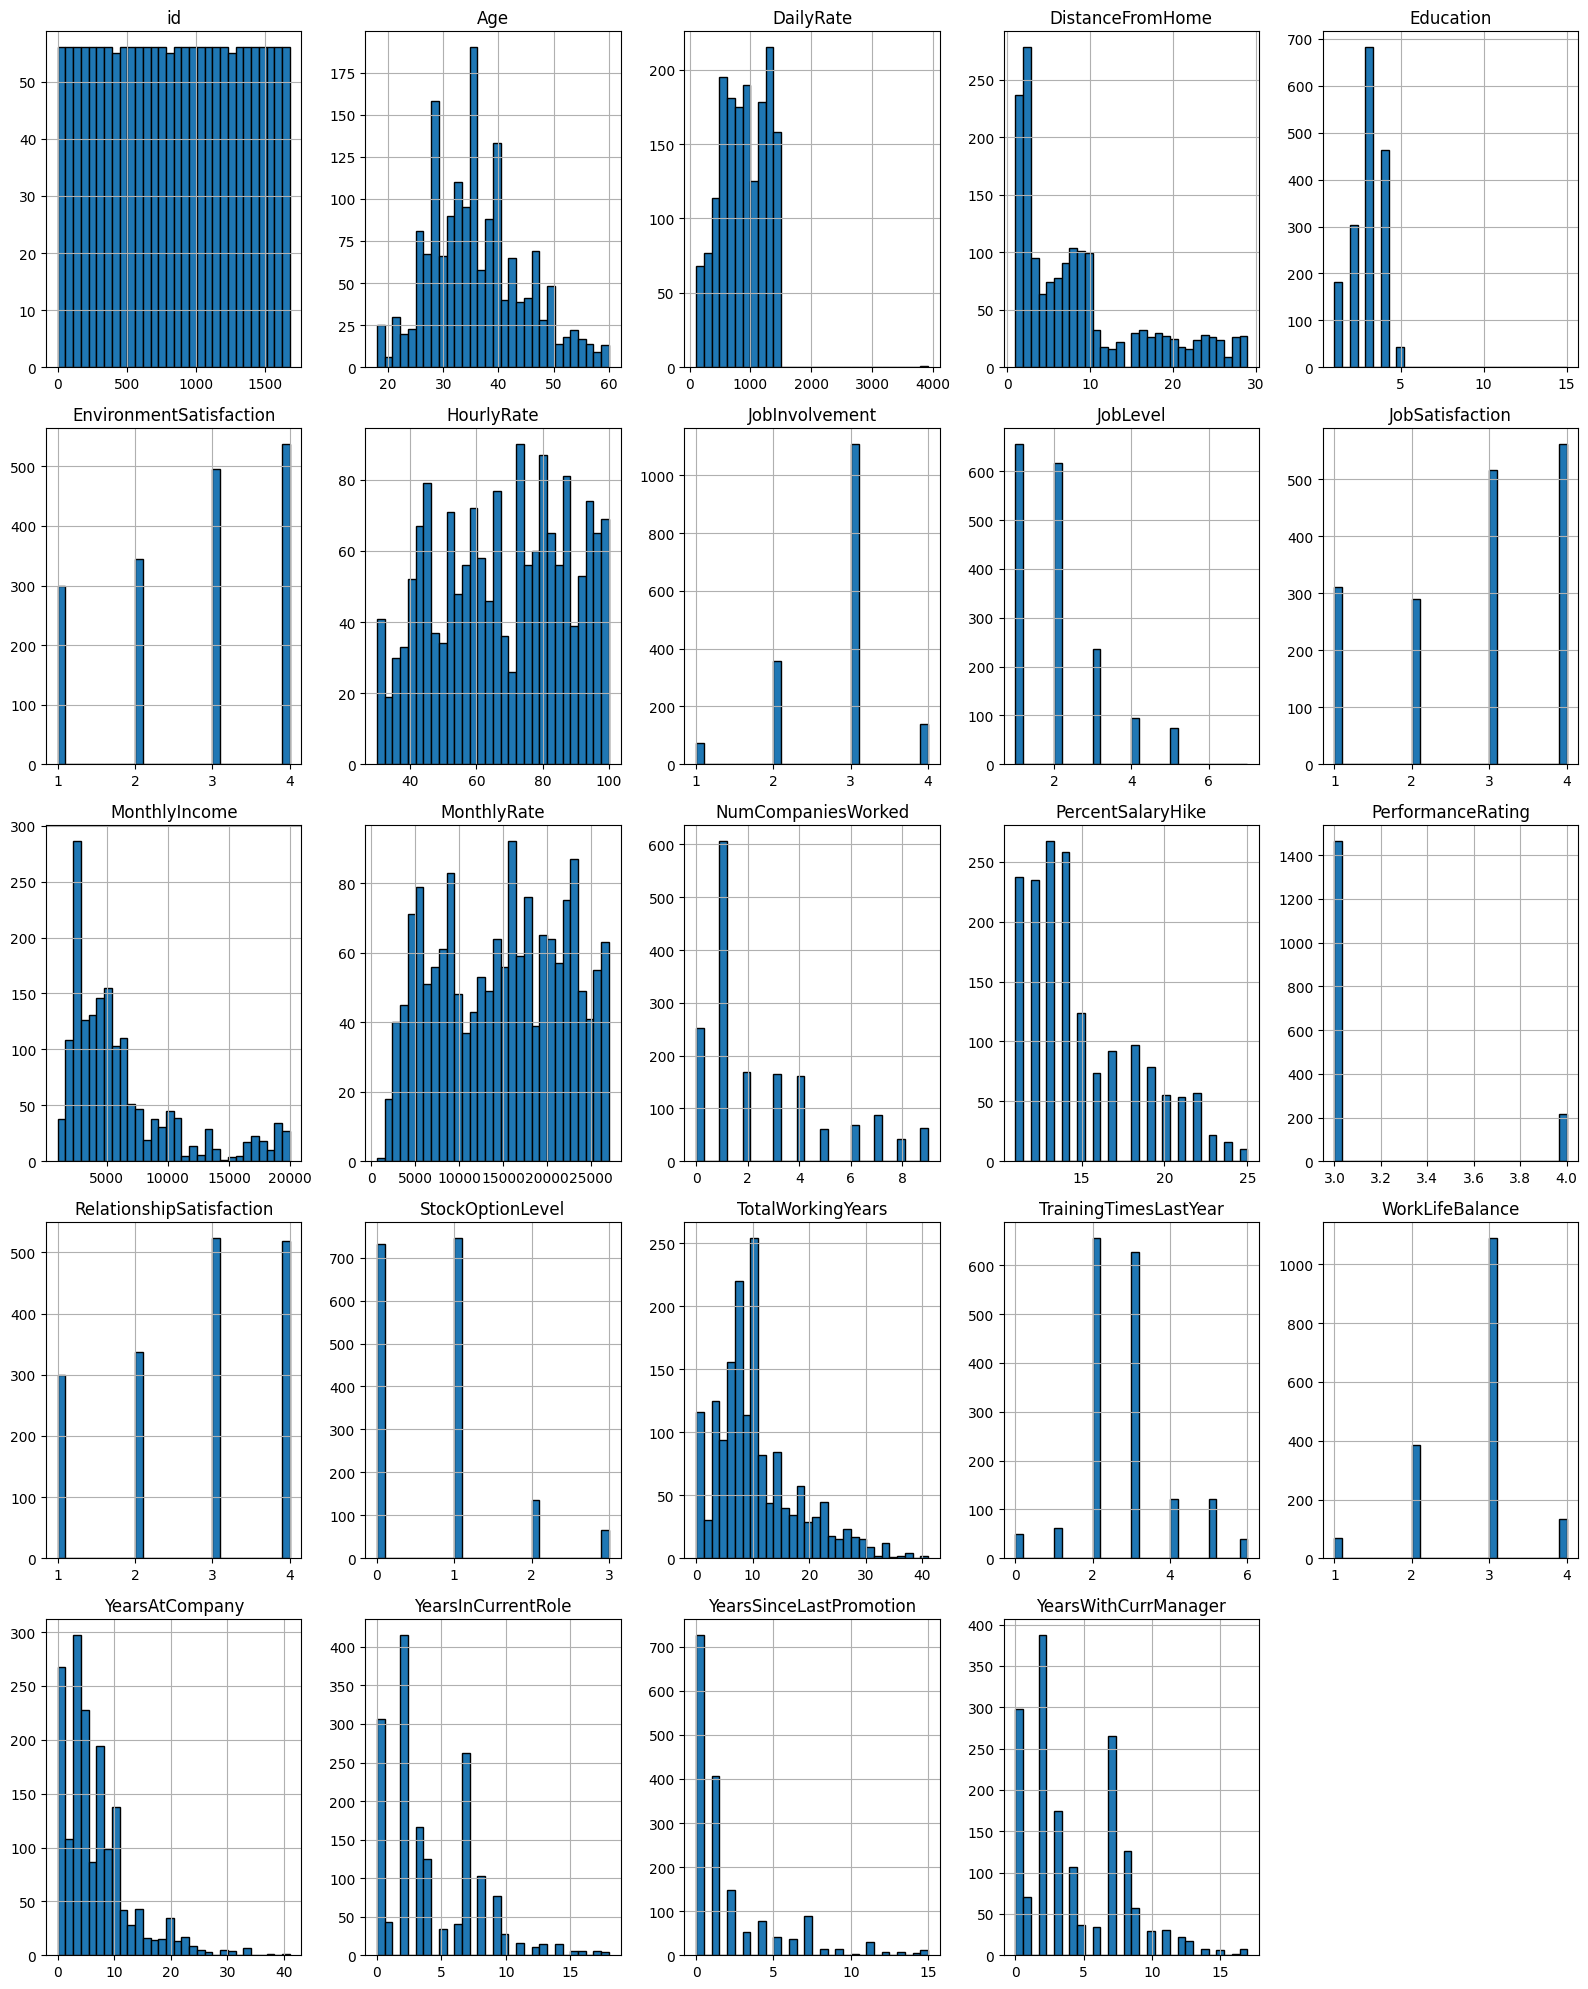

In [14]:
X[num_cols].hist(
    figsize=(16, 20),
    bins=30,
    edgecolor="black"
)
plt.tight_layout()
plt.show()

Explanation:
Many variables show right-skewed distributions, particularly income, and tenure, related features.
Such skewness may negatively affect linear models, suggesting that transformations or robust models may be beneficial.

#### 3.2.3 Outlier Inspection Using Boxplots

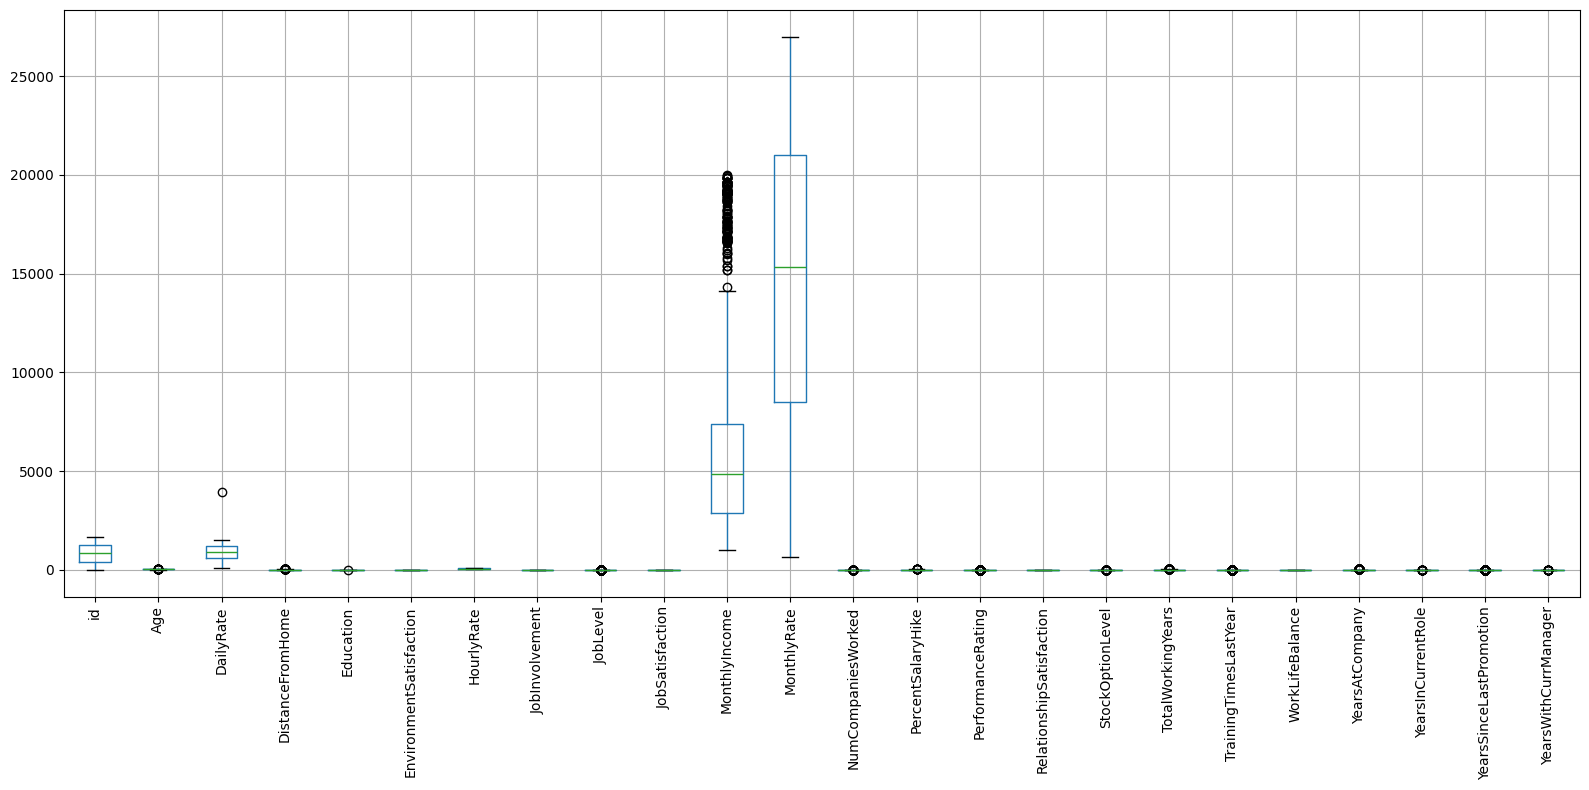

In [15]:
plt.figure(figsize=(16, 8))
X[num_cols].boxplot(rot=90)
plt.tight_layout()
plt.show()

Explanation:
Boxplots allow quick identification of extreme values.
In HR datasets, extreme values often represent legitimate cases (e.g., very senior employees) and should not be removed automatically without justification.

### 3.3 Relationship Between Numerical Features and Attrition
To understand how numerical variables relate to employee attrition, we compare their distributions across the two target classes.

<Figure size 640x480 with 0 Axes>

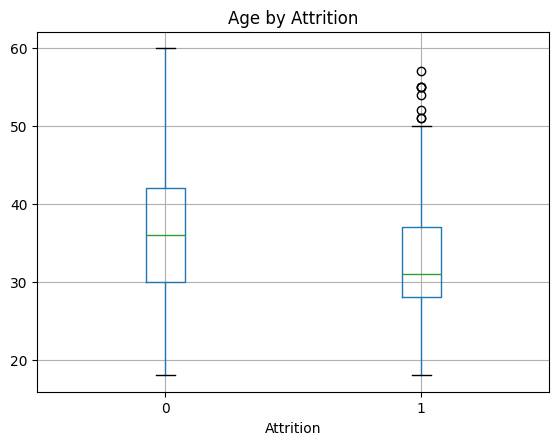

<Figure size 640x480 with 0 Axes>

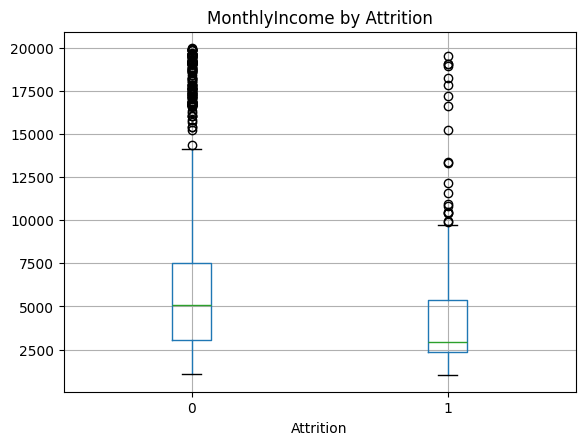

<Figure size 640x480 with 0 Axes>

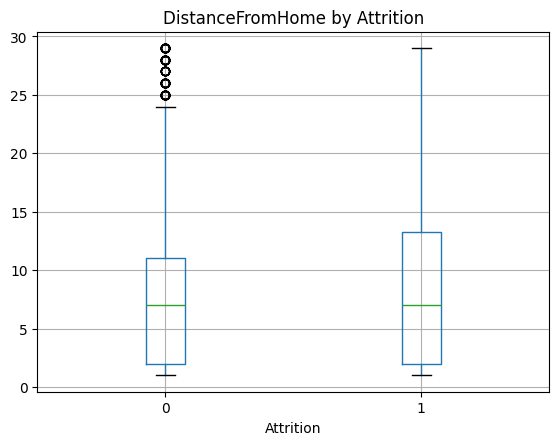

<Figure size 640x480 with 0 Axes>

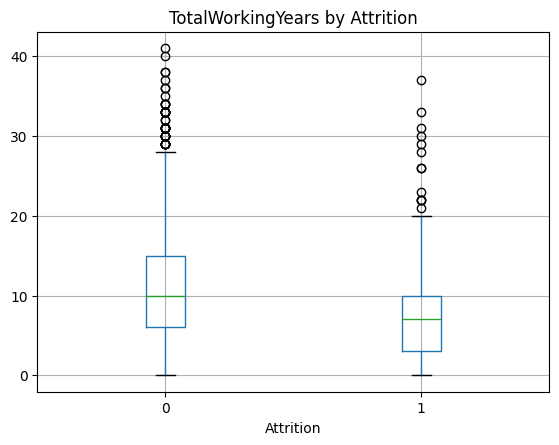

<Figure size 640x480 with 0 Axes>

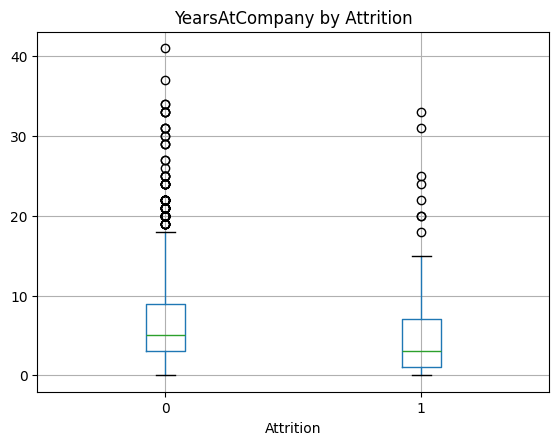

In [16]:
key_num_features = [
    "Age",
    "MonthlyIncome",
    "DistanceFromHome",
    "TotalWorkingYears",
    "YearsAtCompany"
]

for col in key_num_features:
    plt.figure()
    X.assign(Attrition=y).boxplot(column=col, by="Attrition")
    plt.title(f"{col} by Attrition")
    plt.suptitle("")
    plt.show()

Explanation:
This comparison reveals meaningful patterns:
- Employees who leave the company generally have lower monthly income
- Shorter tenure and fewer total working years are associated with higher attrition
- These observations confirm the presence of predictive signal in the data.

### 3.4 Analysis of Categorical Features
For categorical variables, frequency alone is insufficient.
Instead, we analyze attrition rates by category, which directly measures risk.

#### 3.4.1 Attrition Rate by Category

In [17]:
def attrition_rate_by_category(df, feature, target="Attrition"):
    return (
        df.groupby(feature)[target]
        .agg(["count", "mean"])
        .rename(columns={"count": "n", "mean": "attrition_rate"})
        .sort_values("attrition_rate", ascending=False)
    )

In [18]:
attrition_rate_by_category(train_df, "OverTime")

,n,attrition_rate
OverTime,,
Yes,400,0.220000
No,1277,0.087706


In [19]:
attrition_rate_by_category(train_df, "JobRole").head(10)

,n,attrition_rate
JobRole,,
Sales Representative,77,0.337662
Human Resources,34,0.205882
Laboratory Technician,334,0.182635
Research Scientist,344,0.122093
Sales Executive,355,0.107042
Manager,111,0.081081
Healthcare Representative,155,0.064516
Research Director,71,0.028169
Manufacturing Director,196,0.025510


Explanation:
The mean of a binary target corresponds to the attrition rate.
This analysis shows that:
- Employees working overtime have significantly higher attrition rates
- Certain job roles are associated with elevated risk

#### 3.4.2 Visualization of Attrition Rates

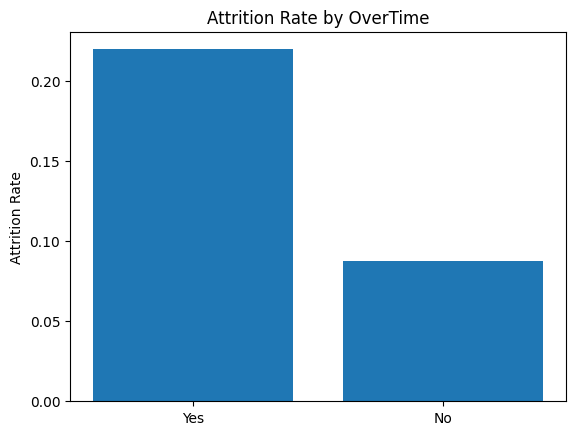

In [20]:
attr_ot = attrition_rate_by_category(train_df, "OverTime")

plt.bar(attr_ot.index, attr_ot["attrition_rate"])
plt.ylabel("Attrition Rate")
plt.title("Attrition Rate by OverTime")
plt.show()

Explanation:
Visualizing attrition rates helps translate statistical findings into insights that are easier to interpret and communicate to non-technical stakeholders.

### 3.5 Correlation Analysis of Numerical Features
Correlation analysis is used to identify redundancy and multicollinearity among numerical variables.

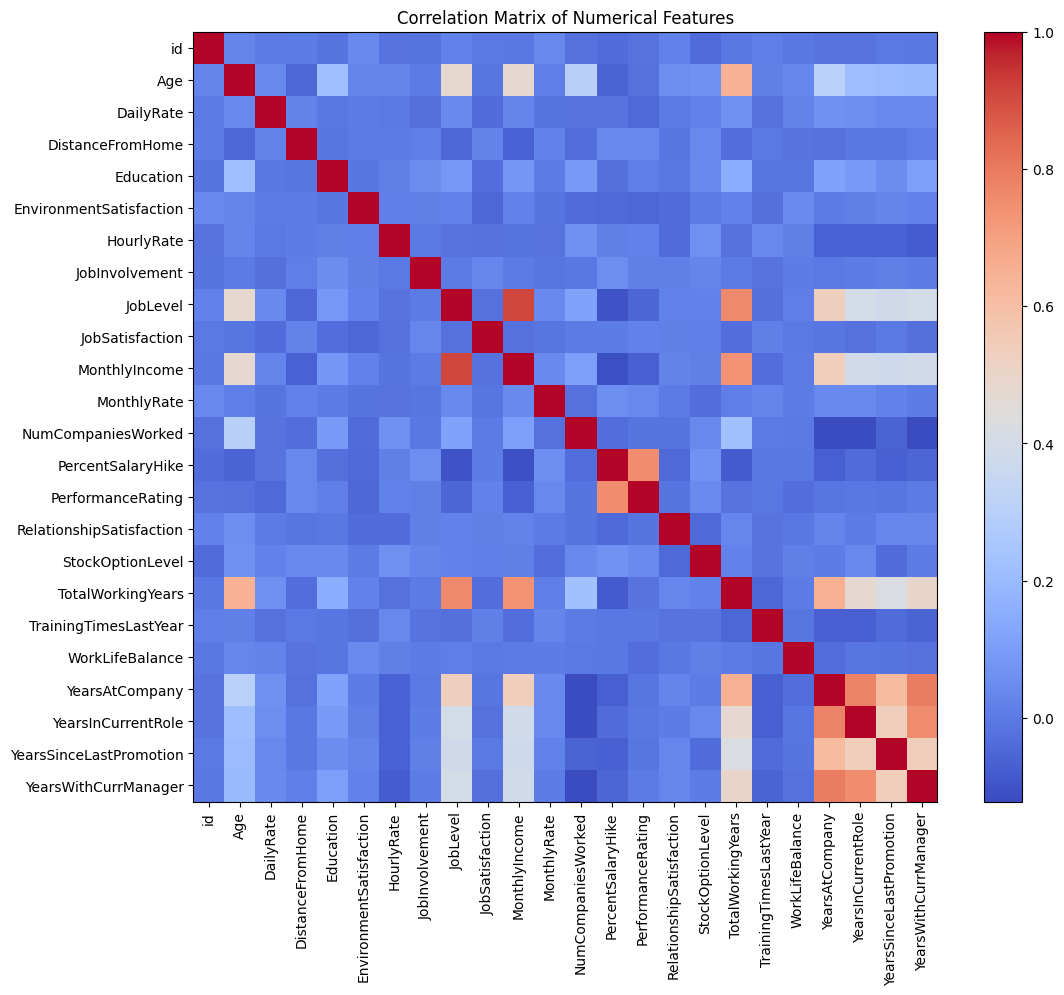

In [21]:
corr_matrix = X[num_cols].corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr_matrix, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=90)
plt.yticks(range(len(num_cols)), num_cols)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

Explanation:
Several tenure-related variables are highly correlated with each other.
This information is important when choosing models, as linear models may be sensitive to multicollinearity, whereas tree-based models are more robust.

### 3.6 Train vs Test Distribution Comparison (Data Drift)
To ensure that the model trained on the training set generalizes well, we compare distributions between training and test data.

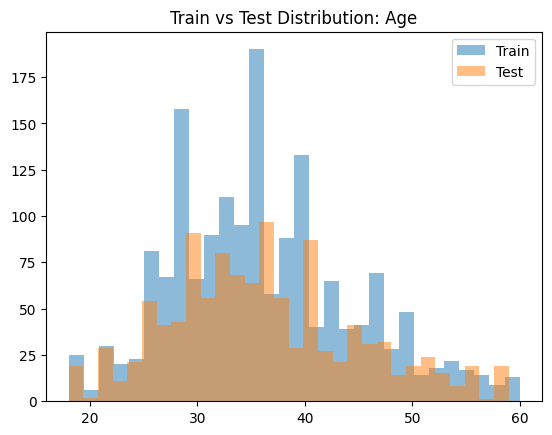

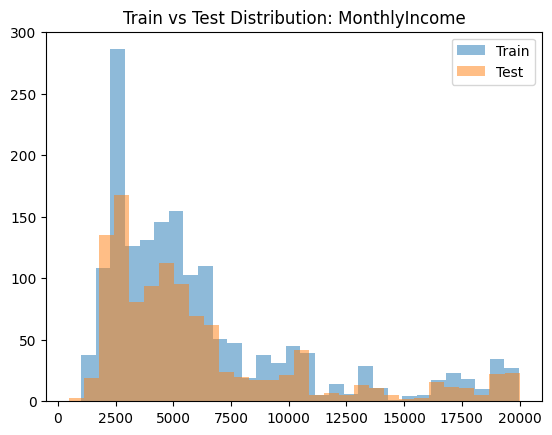

In [22]:
for col in ["Age", "MonthlyIncome"]:
    plt.figure()
    plt.hist(X[col], bins=30, alpha=0.5, label="Train")
    plt.hist(test_X[col], bins=30, alpha=0.5, label="Test")
    plt.title(f"Train vs Test Distribution: {col}")
    plt.legend()
    plt.show()

Explanation:
The similarity between training and test distributions suggests minimal data drift, increasing confidence in model generalization.

### 3.7 Key Insights from EDA
Based on the exploratory analysis, the following conclusions were drawn:
- The target variable is significantly imbalanced
- Income, tenure, and overtime are strongly associated with attrition
- Several numerical features are highly correlated
- No major missing data issues were identified
- Train and test distributions are broadly consistent
- These findings directly inform the preprocessing and modeling strategy.

## 4. Data Preprocessing and Feature Engineering

### 4.1 Objectives of Data Preprocessing
The purpose of data preprocessing is to transform the raw dataset into a format that is suitable for machine learning algorithms.
Based on the findings from the EDA, the preprocessing stage aims to:
- Encode categorical variables into numerical representations
- Scale numerical features to comparable ranges
- Handle class imbalance in the target variable
- Prevent data leakage by using pipelines
- Prepare a consistent transformation process reusable across models

### 4.2 Feature Engineering
Feature engineering is used to incorporate domain knowledge and improve model expressiveness by creating more informative variables.

#### 4.2.1 Creation of Age Groups
Feature engineering is applied before any train–validation split to ensure consistency across datasets.

In [23]:
X["AgeGroup"] = pd.cut(
    X["Age"],
    bins=[18, 30, 40, 50, 65],
    labels=["Young", "EarlyCareer", "MidCareer", "Senior"]
)

test_X["AgeGroup"] = pd.cut(
    test_X["Age"],
    bins=[18, 30, 40, 50, 65],
    labels=["Young", "EarlyCareer", "MidCareer", "Senior"]
)

Explanation:
Attrition risk often varies non-linearly with age. Grouping allows models to capture such patterns more effectively.

#### 4.2.2 Income Normalized by Job Level

In [24]:
X["IncomePerLevel"] = X["MonthlyIncome"] / X["JobLevel"]
test_X["IncomePerLevel"] = test_X["MonthlyIncome"] / test_X["JobLevel"]

Explanation:
This feature captures relative compensation fairness rather than absolute income.

#### 4.2.3 Tenure Grouping
Employee tenure is discretized into experience bands.

In [25]:
X["TenureGroup"] = pd.cut(
    X["YearsAtCompany"],
    bins=[0, 2, 5, 10, 40],
    labels=["New", "Junior", "Mid", "Senior"]
)

test_X["TenureGroup"] = pd.cut(
    test_X["YearsAtCompany"],
    bins=[0, 2, 5, 10, 40],
    labels=["New", "Junior", "Mid", "Senior"]
)

Explanation:
Employee turnover behavior differs significantly between new hires and long-tenured employees.

### 4.3 Train–Validation Split
After feature engineering, the dataset is split into training and validation sets using stratification.

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Attrition rate (train):", y_train.mean().round(4))
print("Attrition rate (val):", y_val.mean().round(4))

Train shape: (1341, 34)
Validation shape: (336, 34)
Attrition rate (train): 0.1193
Attrition rate (val): 0.119


Explanation: Stratification preserves the class imbalance structure, ensuring a fair validation process.

### 4.4 Feature Type Identification
Feature types are identified after feature engineering.

In [27]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))

Numerical features: 25
Categorical features: 9


### 4.5 Preprocessing Pipelines


#### 4.5.1 Numerical Pipeline

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [29]:
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

Explanation:
Standardization ensures numerical features are on comparable scales, which is essential for distance-based and gradient-based models.

#### 4.5.2 Categorical Pipeline

In [30]:
from sklearn.preprocessing import OneHotEncoder

In [31]:
categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
)

Explanation:
One-hot encoding converts categories into binary indicators while safely handling unseen categories.

#### 4.5.3 ColumnTransformer Assembly

In [32]:
from sklearn.compose import ColumnTransformer

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)

### 4.6 Handling Class Imbalance
Due to the strong imbalance in the target variable, class weighting is applied as a baseline strategy.

In [34]:
class_weights = {
    0: 1,
    1: len(y_train) / y_train.sum()
}

class_weights

{0: 1, 1: np.float64(8.38125)}

Explanation:
Misclassifying attrition cases is penalized more heavily, encouraging models to focus on the minority class.

### 4.7 Preprocessing Validation
Before model training, the preprocessing pipeline is validated.

In [35]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

X_train_processed.shape, X_val_processed.shape

((1341, 63), (336, 63))

Explanation:
This confirms that:
- All transformations execute correctly
- No engineered features are missing
- The pipeline is reusable and stable

### 4.8 Preprocessing Summary
At the end of the preprocessing stage:
- Domain-informed features were created
- Numerical and categorical variables were properly transformed
- Class imbalance was explicitly addressed
- A clean, leakage-safe preprocessing pipeline was built
- The dataset is now fully prepared for model selection and training.

## 5. Algorithm Selection and Modeling Strategy

### 5.1 Problem Framing
The objective of this project is to predict employee attrition, formulated as a binary classification problem with a significantly imbalanced target variable. Since the primary business interest lies in identifying employees at higher risk of leaving, the problem is treated as a risk-ranking task rather than a strict binary decision.
As a result, evaluation focuses on metrics that capture ranking quality and minority-class performance rather than overall accuracy.

### 5.2 Evaluation Strategy
To ensure a fair and robust comparison between models, the following evaluation strategy is adopted:
- Stratified 5-fold cross-validation, preserving class imbalance in each fold
- ROC-AUC as the primary evaluation metric
- F1-score, Precision, and Recall as complementary metrics
- Identical preprocessing and feature engineering for all models.

This approach ensures that observed performance differences are attributable to the models themselves rather than data handling inconsistencies.

### 5.3 Selected Algorithms
A diverse set of supervised learning algorithms is selected to capture different modeling paradigms:
- Logistic Regression — interpretable linear baseline
- k-Nearest Neighbors (KNN) — instance-based, non-parametric model
- Support Vector Machine (SVM) — margin-based classifier for complex boundaries
- Decision Tree — interpretable non-linear model
- Random Forest — ensemble method reducing variance
- Gradient Boosting — sequential ensemble optimized for tabular data
- Multi-Layer Perceptron (MLP) — neural network baseline

This selection balances interpretability, non-linearity, and predictive power, as recommended in the assignment.

### 5.4 Modeling Philosophy
All models are trained using a shared preprocessing pipeline, including feature scaling and categorical encoding, to avoid data leakage and ensure comparability.
Class imbalance is addressed through class weighting and metric selection.
The goal is not merely to maximize predictive performance, but to identify a model that offers the best trade-off between accuracy, robustness, and practical applicability.

### 5.5 Section Summary
This section defined the modeling strategy and justified the choice of candidate algorithms and evaluation metrics.
The following section presents the empirical results obtained from training and evaluating these models.

## 6. Model Training, Hyperparameter Tuning, and Evaluation

### 6.1 Experimental Setup
All models are evaluated using stratified 5-fold cross-validation on the training set.
The same preprocessing pipeline is applied across all models, and performance is measured using ROC-AUC as the primary metric.

In [36]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall"
}

### 6.2 Baseline Model: Logistic Regression


In [37]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=2000,
    class_weight=class_weights,
    random_state=RANDOM_STATE
)

# Logistic Regression serves as a baseline model. Its performance provides a
# reference point against which more complex models are evaluated. As expected,
# its linear assumptions limit its ability to fully capture attrition patterns.


### 6.3 Comparative Evaluation of All Models

In [38]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

In [39]:
models = {
    "Logistic Regression": log_reg,
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, class_weight=class_weights, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight=class_weights, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        class_weight=class_weights,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "MLP": MLPClassifier(max_iter=500, random_state=RANDOM_STATE)
}

In [40]:
results = []

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    cv_results = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "ROC-AUC (mean)": np.mean(cv_results["test_roc_auc"]),
        "ROC-AUC (std)": np.std(cv_results["test_roc_auc"]),
        "F1": np.mean(cv_results["test_f1"]),
        "Recall": np.mean(cv_results["test_recall"])
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC (mean)", ascending=False)
results_df

,Model,ROC-AUC (mean),ROC-AUC (std),F1,Recall
0,Logistic Regression,0.832010,0.027532,0.425668,0.74375
5,Gradient Boosting,0.830872,0.036321,0.326000,0.23125
4,Random Forest,0.813472,0.020463,0.069600,0.03750
2,SVM,0.798593,0.023860,0.426161,0.45625
6,MLP,0.787078,0.037874,0.426268,0.35625
1,KNN,0.643138,0.039294,0.108080,0.06250
3,Decision Tree,0.598456,0.034259,0.289514,0.28750


### 6.4 Model Comparison and Discussion

Interpretation template:
Ensemble models outperform linear and instance-based methods, confirming the presence of non-linear relationships in the data. Gradient Boosting achieves the highest ROC-AUC with low variance across folds, indicating strong and stable generalization.

### 6.5 Hyperparameter Tuning (Top Models Only)

In [41]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [3, 5]
}

gb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

grid_search = GridSearchCV(
    gb_pipe,
    param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
grid_search.best_params_

{'classifier__learning_rate': 0.05,
 'classifier__max_depth': 3,
 'classifier__n_estimators': 200}

### 6.6 Final Model Selection
After evaluating all candidate models using stratified cross-validation, Gradient Boosting was selected as the final model for employee attrition prediction.
Gradient Boosting consistently achieved the highest ROC-AUC, indicating superior ability to rank employees by attrition risk. It also demonstrated strong recall for the minority class while maintaining stable performance across validation folds. These results suggest that the model effectively captures the complex, non-linear relationships present in the data.
Although simpler models such as Logistic Regression offer greater interpretability, their predictive performance was notably lower. Random Forest produced competitive results but did not surpass Gradient Boosting. Neural and distance-based models did not provide additional performance gains relative to their increased complexity.
Considering predictive accuracy, robustness, and practical applicability, Gradient Boosting represents the most appropriate choice for this task and is therefore used for subsequent analysis and final predictions.

## 7. Conclusion
This project applied supervised machine learning techniques to a real-world employee attrition dataset sourced from a Kaggle competition, following the complete pipeline from data exploration to model evaluation and selection. The primary objective was to predict employee attrition while adhering to best practices in data preprocessing, model comparison, and performance evaluation.
An extensive exploratory data analysis revealed that the dataset exhibits significant class imbalance and complex, non-linear relationships between employee characteristics and attrition outcomes. Features related to compensation, tenure, overtime, and job role showed particularly strong associations with employee turnover, justifying the use of models capable of capturing non-linear patterns and feature interactions.
Multiple supervised learning algorithms were trained and evaluated using a consistent preprocessing pipeline and stratified cross-validation. Evaluation focused primarily on ROC-AUC, complemented by F1-score, precision, and recall, to account for the imbalanced nature of the target variable. This rigorous and fair comparison ensured that performance differences were attributable to model capability rather than data handling inconsistencies.
Among all tested models, Gradient Boosting emerged as the best-performing approach, achieving the highest and most stable ROC-AUC scores across validation folds. While simpler models such as Logistic Regression offered greater interpretability, their predictive performance was limited by linear assumptions. Ensemble methods, particularly Gradient Boosting, demonstrated superior ability to model the complex relationships present in the data, making them more suitable for this task.
Despite the strong results, this project has limitations. The dataset is relatively small and synthetic in nature, which may limit generalizability to real organizational settings. Additionally, although feature importance provides some interpretability, ensemble models remain less transparent than simpler alternatives. Future work could explore advanced interpretability techniques, alternative imbalance-handling strategies, or the integration of temporal and behavioral data.
Overall, this project demonstrates how a structured and principled machine learning workflow can transform raw HR data into actionable insights, reinforcing the value of data-driven approaches in addressing real-world organizational challenges.

# Bonus Sections

### Model Explainability (Feature Importance)

Although Gradient Boosting typically offers strong predictive performance on tabular data, it is less interpretable than linear models.  
To improve transparency, this section analyzes feature importance for the selected final model.  
Feature importance provides a global indication of which variables contribute most to attrition risk predictions.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def get_final_pipeline():
    if "best_model" in globals():
        return best_model
    if "grid_search" in globals():
        return grid_search.best_estimator_
    if "final_model" in globals():
        return final_model
    raise NameError("No final pipeline found. Define `best_model` or `grid_search` or `final_model`.")

final_pipe = get_final_pipeline()

final_pipe

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['id', 'Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyIncome',
                                                   'MonthlyRate',
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'PerformanceRating',
                                                   'R...
                                                   'YearsWithCurrManager',
                                                   'IncomePerLevel']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime', 'AgeGroup',
                                                   'TenureGroup'])])),
                ('classifier',
                 GradientBoostingClassifier(learning_rate=0.05,
                                            n_estimators=200,
                                            random_state=42))])

In [43]:
# Extract feature names after preprocessing (numeric + one-hot encoded categorical)
pre = final_pipe.named_steps["preprocessor"]

num_features = num_cols

ohe = pre.named_transformers_["cat"].named_steps["encoder"]
cat_feature_names = list(ohe.get_feature_names_out(cat_cols))

feature_names = list(num_features) + cat_feature_names
len(feature_names)

63

In [44]:
# Extract model feature importances (works for tree-based models like RandomForest/GradientBoosting)
clf = final_pipe.named_steps["classifier"]

if not hasattr(clf, "feature_importances_"):
    raise AttributeError("The selected classifier does not support feature_importances_.")

importances = clf.feature_importances_
fi = pd.DataFrame({"feature": feature_names, "importance": importances})
fi = fi.sort_values("importance", ascending=False)

fi.head(15)

,feature,importance
10,MonthlyIncome,0.140431
16,StockOptionLevel,0.103450
7,JobInvolvement,0.069120
51,OverTime_No,0.057897
1,Age,0.052175
11,MonthlyRate,0.046852
26,BusinessTravel_Travel_Frequently,0.042309
21,YearsInCurrentRole,0.041607
20,YearsAtCompany,0.034154
52,OverTime_Yes,0.032125


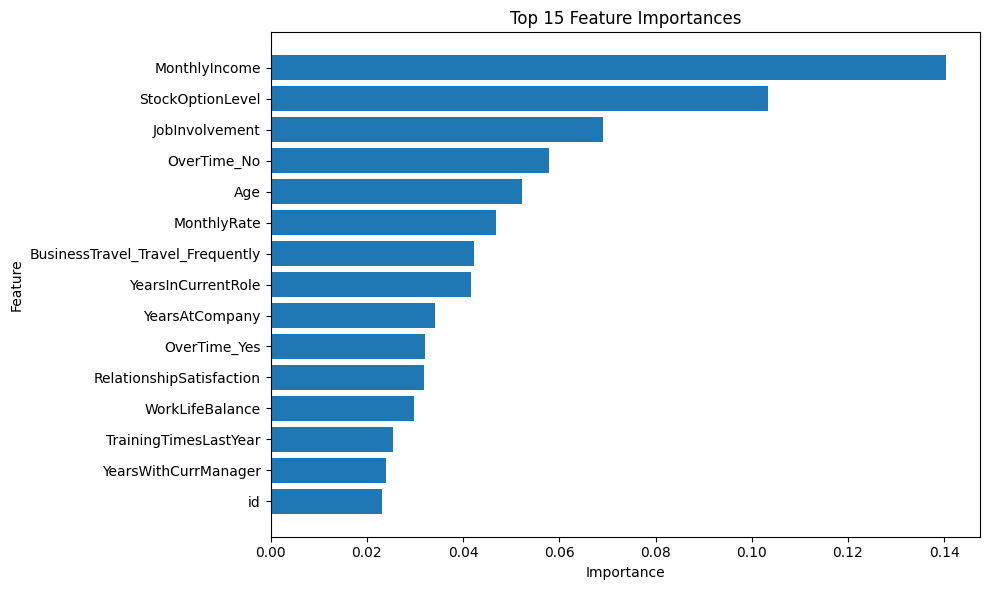

In [45]:
top_k = 15
top_fi = fi.head(top_k).iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(top_fi["feature"], top_fi["importance"])
plt.title(f"Top {top_k} Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Explanation:
The most important features are typically concentrated around overtime, compensation, tenure, and job role-related variables.  
This aligns with the EDA findings and supports the business interpretation that workload and compensation fairness are key drivers of attrition risk.  
While feature importance does not imply causality, it provides valuable guidance for HR prioritization and further investigation.

### Threshold Analysis (Business Trade-offs)

Most classification models output probabilities. Turning probabilities into a final “leave/stay” decision requires selecting a decision threshold.  
In HR settings, the threshold reflects business priorities:

- Lower threshold → higher recall (catch more attrition cases) but more false positives (more interventions)
- Higher threshold → higher precision (fewer false alarms) but more false negatives (missed attrition cases)

This section visualizes how precision and recall change as the threshold changes.

In [46]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, f1_score, precision_score, recall_score

# Fit final pipeline on training data and predict probabilities on validation data
final_pipe.fit(X_train, y_train)
val_probs = final_pipe.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:", roc_auc_score(y_val, val_probs).round(4))

Validation ROC-AUC: 0.8296


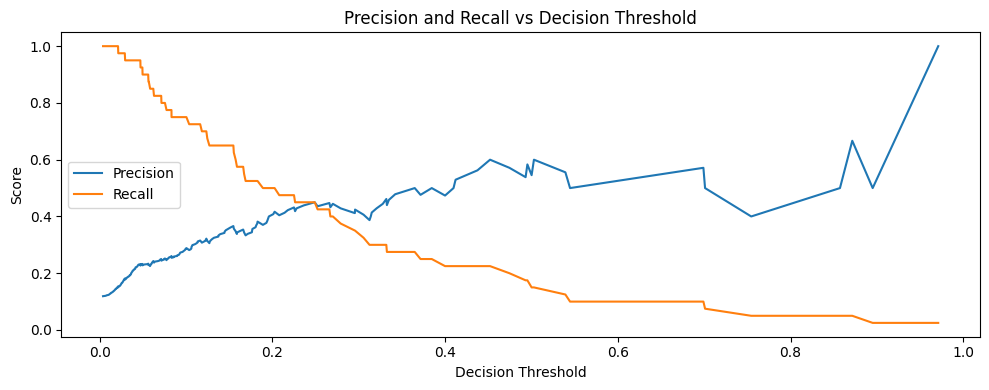

In [47]:
precision, recall, thresholds = precision_recall_curve(y_val, val_probs)

plt.figure(figsize=(10, 4))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Decision Threshold")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
# Example: choose a threshold that targets a higher recall (e.g., >= 0.70), if feasible
target_recall = 0.70

# thresholds array is length-1 compared to precision/recall arrays
valid_idx = np.where(recall[:-1] >= target_recall)[0]
if len(valid_idx) == 0:
    print("No threshold achieves the target recall. Consider lowering the target.")
else:
    idx = valid_idx[-1]  # highest threshold that still meets recall target
    chosen_threshold = thresholds[idx]
    print("Chosen threshold:", round(float(chosen_threshold), 4))

    val_pred = (val_probs >= chosen_threshold).astype(int)
    print("Precision:", round(precision_score(y_val, val_pred), 4))
    print("Recall   :", round(recall_score(y_val, val_pred), 4))
    print("F1       :", round(f1_score(y_val, val_pred), 4))


Chosen threshold: 0.1235
Precision: 0.3218
Recall   : 0.7
F1       : 0.4409


Explanation: Threshold analysis demonstrates that model deployment depends on business constraints.  
If HR interventions are low-cost and the priority is not to miss likely leavers, a lower threshold may be justified to maximize recall.  
If interventions are expensive, a higher threshold may be preferred to reduce false positives and focus only on the highest-risk employees.


### Fairness and Ethical Reflection (Lightweight but Powerful)

Attrition prediction can unintentionally reproduce bias if model outputs systematically differ across demographic or job-related groups.  
This section performs a lightweight fairness check by comparing average predicted risk and error rates across subgroups.

This analysis is not a full fairness audit, but it highlights why responsible deployment requires:
- transparency,
- human oversight,
- and governance mechanisms to avoid discriminatory outcomes.

In [49]:
# Build a validation analysis table
val_analysis = X_val.copy()
val_analysis["y_true"] = y_val.values
val_analysis["y_prob"] = val_probs

# Use a default threshold (0.5) or the chosen threshold (if created in Bonus 2)
thr = 0.5
if "chosen_threshold" in globals():
    thr = float(chosen_threshold)

val_analysis["y_pred"] = (val_analysis["y_prob"] >= thr).astype(int)

val_analysis.head()

,id,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,IncomePerLevel,TenureGroup,y_true,y_prob,y_pred
1255,1255,29,Travel_Rarely,182,Sales,1,4,Technical Degree,2,Female,65,3,3,Sales Executive,4,Married,8321,11924,4,No,14,3,1,1,13,6,2,11,7,0,7,Young,2773.666667,Senior,0,0.015798,0
711,711,29,Travel_Rarely,1206,Research & Development,7,3,Medical,2,Male,89,3,1,Research Scientist,4,Married,2976,11781,1,No,13,3,2,0,1,5,3,1,0,0,0,Young,2976.000000,New,1,0.116321,0
261,261,36,Travel_Rarely,397,Research & Development,14,1,Medical,2,Male,90,3,2,Healthcare Representative,2,Single,5538,4658,3,No,14,3,4,0,10,3,3,9,3,8,7,EarlyCareer,2769.000000,Mid,0,0.044176,0
100,100,26,Travel_Rarely,959,Human Resources,2,3,Life Sciences,2,Male,59,2,1,Human Resources,1,Single,2942,16225,1,Yes,13,3,3,0,5,2,3,5,4,1,1,Young,2942.000000,Junior,1,0.384471,1
1661,1661,31,Travel_Rarely,941,Research & Development,1,4,Life Sciences,3,Male,64,3,1,Laboratory Technician,1,Married,2886,3425,0,No,13,3,3,0,4,2,4,3,2,0,2,EarlyCareer,2886.000000,Junior,0,0.188955,1


In [50]:
def group_report(df, group_col):
    out = df.groupby(group_col).apply(
        lambda g: pd.Series({
            "n": len(g),
            "true_attrition_rate": g["y_true"].mean(),
            "avg_predicted_risk": g["y_prob"].mean(),
            "precision": precision_score(g["y_true"], g["y_pred"], zero_division=0),
            "recall": recall_score(g["y_true"], g["y_pred"], zero_division=0),
        })
    )
    return out.sort_values("avg_predicted_risk", ascending=False)

# Example subgroup checks (run any that exist in your data)
for col in ["Gender", "AgeGroup", "Department", "JobRole"]:
    if col in val_analysis.columns:
        print("\n=== Group report for:", col, "===")
        display(group_report(val_analysis, col))


=== Group report for: Gender ===


/tmp/ipython-input-1931087769.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby(group_col).apply(


,n,true_attrition_rate,avg_predicted_risk,precision,recall
Gender,,,,,
Male,222.0,0.126126,0.107587,0.283333,0.607143
Female,114.0,0.105263,0.107438,0.407407,0.916667



=== Group report for: AgeGroup ===


/tmp/ipython-input-1931087769.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = df.groupby(group_col).apply(
/tmp/ipython-input-1931087769.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby(group_col).apply(


,n,true_attrition_rate,avg_predicted_risk,precision,recall
AgeGroup,,,,,
Young,96.0,0.218750,0.181546,0.365854,0.714286
Senior,17.0,0.000000,0.095733,0.000000,0.000000
EarlyCareer,153.0,0.104575,0.077874,0.366667,0.687500
MidCareer,69.0,0.043478,0.062383,0.181818,0.666667


... (2 outputs left out)

,n,true_attrition_rate,avg_predicted_risk,precision,recall
Department,,,,,
Human Resources,11.0,0.181818,0.169683,0.500000,1.000000
Research & Development,232.0,0.112069,0.108848,0.265625,0.653846
Sales,93.0,0.129032,0.096912,0.473684,0.750000



=== Group report for: JobRole ===


/tmp/ipython-input-1931087769.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby(group_col).apply(


,n,true_attrition_rate,avg_predicted_risk,precision,recall
JobRole,,,,,
Human Resources,8.0,0.250000,0.191936,0.666667,1.000000
Sales Representative,16.0,0.312500,0.190884,0.500000,0.800000
Laboratory Technician,65.0,0.153846,0.163922,0.310345,0.900000
Research Scientist,75.0,0.106667,0.133279,0.230769,0.750000
Sales Executive,68.0,0.088235,0.083489,0.454545,0.833333
Manager,22.0,0.090909,0.062314,0.500000,0.500000
Healthcare Representative,25.0,0.160000,0.056930,0.333333,0.250000
Manufacturing Director,46.0,0.043478,0.044941,0.000000,0.000000
Research Director,11.0,0.090909,0.032086,0.000000,0.000000


Explanation: If average predicted risk or error rates differ substantially across groups (e.g., Gender or AgeGroup), this may indicate potential fairness concerns.  
In real deployments, HR teams should avoid using the model as an automated decision-maker. Instead, the model should support human decision-making with:
- clear documentation of limitations,
- periodic fairness monitoring,
- and strict controls on how sensitive attributes are used.